# Project 11: Handwritten Digit Classification Using CNN

**Objective:** Build a Convolutional Neural Network (CNN) to classify handwritten digits from the MNIST dataset and evaluate it using accuracy, a confusion matrix, a classification report, and sample predictions.

**Dataset:** MNIST contains 70,000 grayscale images of handwritten digits (0–9), each sized 28 × 28 pixels. It contains 60,000 training images and 10,000 test images.

**Tools:** Python, TensorFlow/Keras, NumPy, Matplotlib, Seaborn, and Scikit-learn.

## 1. Import required libraries
The libraries below load the dataset, build the CNN, visualize results, and calculate evaluation metrics.

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from sklearn.metrics import confusion_matrix, classification_report

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 2. Load the MNIST dataset
The dataset is divided into training data, used to learn patterns, and testing data, used to evaluate performance on unseen images.

In [22]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


## 3. Visualize sample images
This cell displays ten training images and their labels so the dataset can be inspected before training.

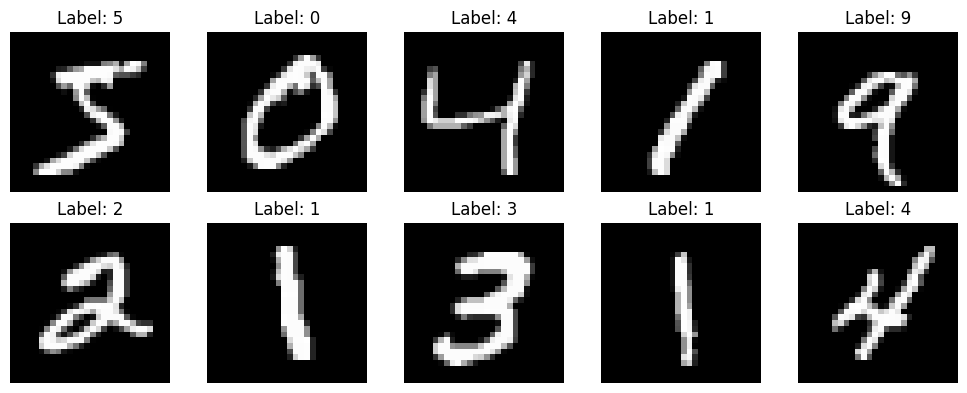

In [10]:
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()

## 4. Preprocess the images
Pixel values are normalized from 0–255 to 0–1. A channel dimension is added because Conv2D expects images in height × width × channels format.

In [11]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print("Preprocessed training shape:", X_train.shape)
print("Preprocessed testing shape:", X_test.shape)

Preprocessed training shape: (60000, 28, 28, 1)
Preprocessed testing shape: (10000, 28, 28, 1)


## 5. Build the CNN model
Convolutional layers learn image features, max-pooling layers reduce feature-map size, Flatten converts the features into a vector, and Dense layers perform classification. Dropout helps reduce overfitting.

In [12]:
model = Sequential([
    Conv2D(32, (3, 3), activation="relu", input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.3),
    Dense(10, activation="softmax")
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Compile the model
Adam updates model weights during training. Sparse categorical cross-entropy is suitable because the labels are integer digits from 0 to 9. Accuracy is tracked as a metric.

In [13]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

## 7. Train the model
The model trains for five epochs with batches of 64 images. Ten percent of the training data is used for validation. Training may take a few minutes depending on the environment.

In [14]:

history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.9351 - loss: 0.2135 - val_accuracy: 0.9842 - val_loss: 0.0574
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9790 - loss: 0.0692 - val_accuracy: 0.9912 - val_loss: 0.0365
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9840 - loss: 0.0498 - val_accuracy: 0.9907 - val_loss: 0.0351
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9880 - loss: 0.0388 - val_accuracy: 0.9892 - val_loss: 0.0352
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9908 - loss: 0.0292 - val_accuracy: 0.9905 - val_loss: 0.0316


## 8. Plot training accuracy and loss
Training and validation curves help show whether the model is learning and whether the training and validation performance diverge.

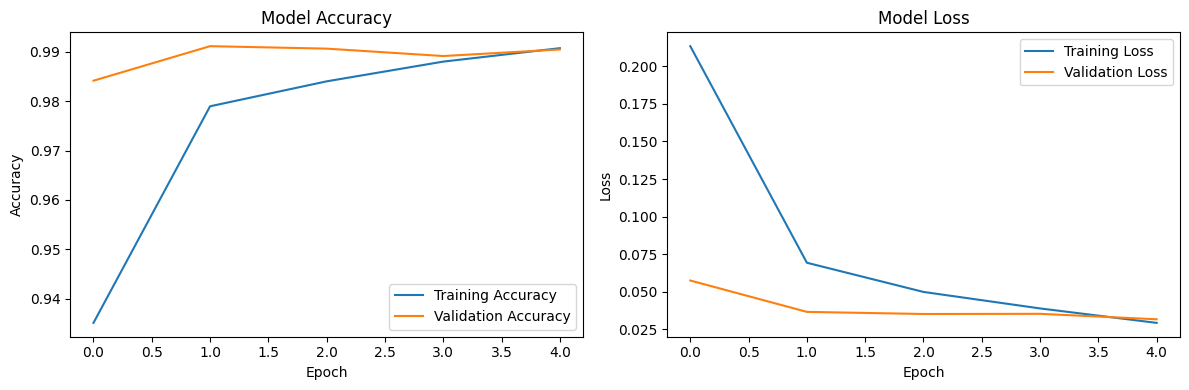

In [15]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

## 9. Evaluate on the test dataset
The test dataset contains images not used for gradient updates or validation. Record the accuracy and loss printed by your own run in the final report.

In [16]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Loss: 0.0322
Test Accuracy: 98.99%


## 10. Predict test images
The model returns ten class probabilities for each image. `argmax` selects the digit with the highest predicted probability.

In [17]:
y_prob = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print("Actual labels:   ", y_test[:10])
print("Predicted labels:", y_pred[:10])

Actual labels:    [7 2 1 0 4 1 4 9 5 9]
Predicted labels: [7 2 1 0 4 1 4 9 5 9]


## 11. Confusion matrix
Rows represent actual digits and columns represent predicted digits. Values on the diagonal are correct predictions; off-diagonal values show misclassifications.

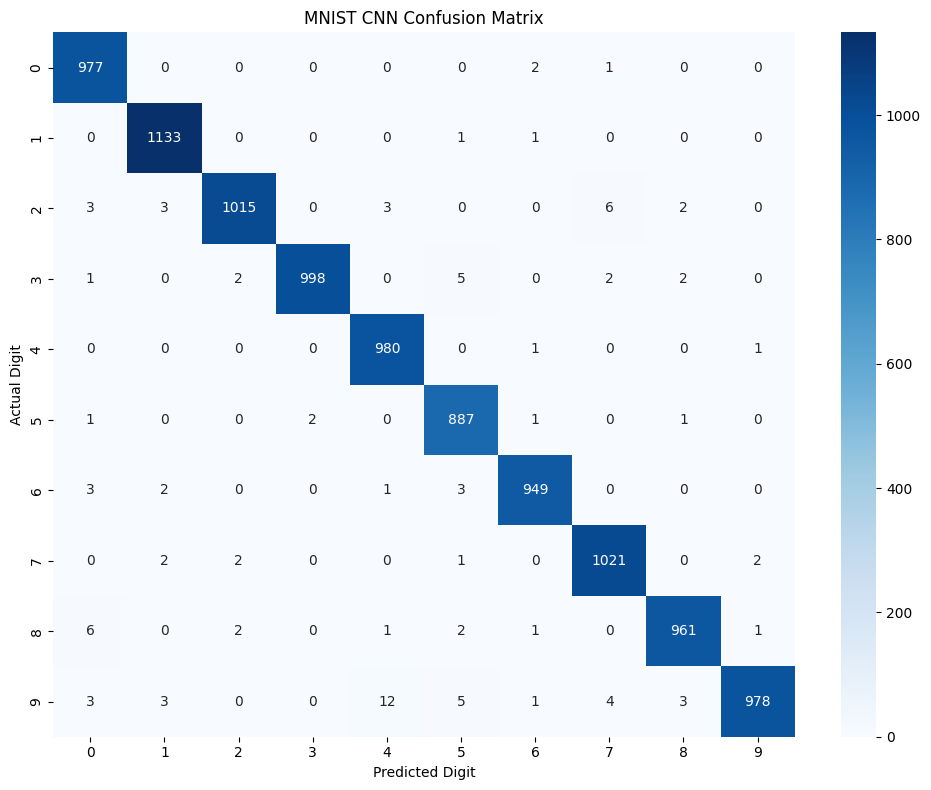

In [18]:
cm = confusion_matrix(y_test, y_pred, labels=range(10))

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=range(10),
    yticklabels=range(10)
)
plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.title("MNIST CNN Confusion Matrix")
plt.tight_layout()
plt.show()

## 12. Classification report
Precision measures how many predictions for a digit were correct. Recall measures how many actual examples of a digit were found. F1-score balances precision and recall, while support is the number of test examples for each digit.

In [19]:
print(classification_report(
    y_test,
    y_pred,
    labels=range(10),
    target_names=[str(i) for i in range(10)],
    digits=4,
    zero_division=0
))

              precision    recall  f1-score   support

           0     0.9829    0.9969    0.9899       980
           1     0.9913    0.9982    0.9947      1135
           2     0.9941    0.9835    0.9888      1032
           3     0.9980    0.9881    0.9930      1010
           4     0.9829    0.9980    0.9904       982
           5     0.9812    0.9944    0.9878       892
           6     0.9927    0.9906    0.9916       958
           7     0.9874    0.9932    0.9903      1028
           8     0.9917    0.9867    0.9892       974
           9     0.9959    0.9693    0.9824      1009

    accuracy                         0.9899     10000
   macro avg     0.9898    0.9899    0.9898     10000
weighted avg     0.9900    0.9899    0.9899     10000



## 13. Visualize sample predictions
Green titles indicate correct predictions and red titles indicate incorrect predictions.

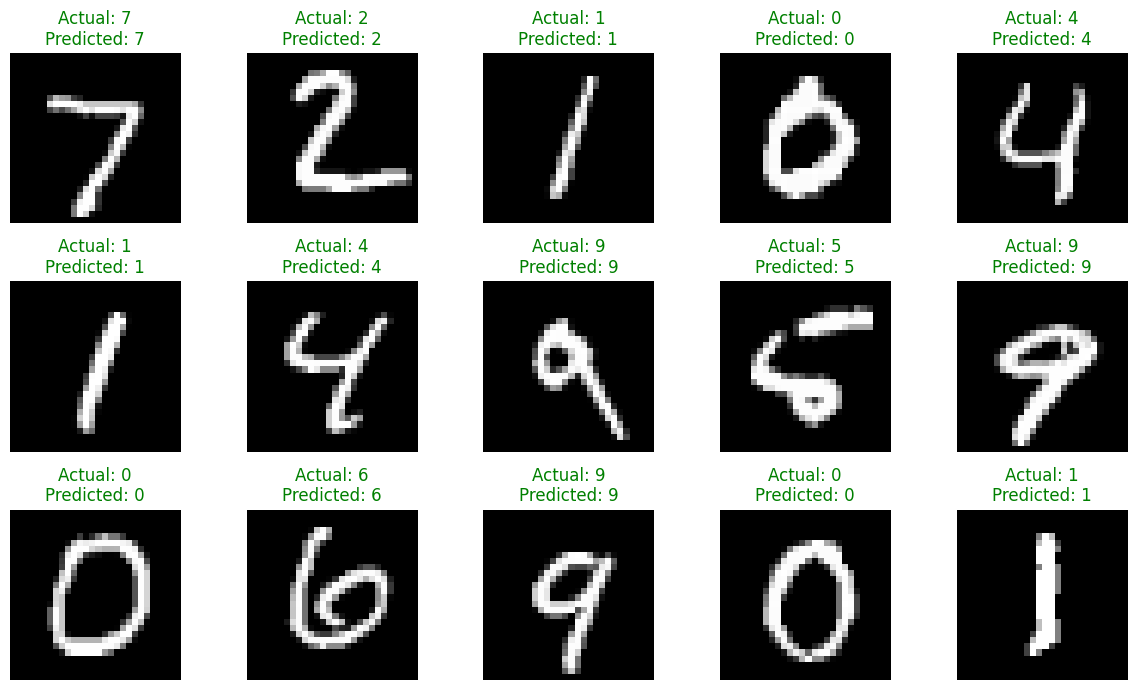

In [20]:
plt.figure(figsize=(12, 7))

for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(X_test[i].squeeze(), cmap="gray")
    actual = y_test[i]
    predicted = y_pred[i]
    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}",
        color="green" if actual == predicted else "red"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

## 14. Save the trained model
The trained model is saved in Keras format and can be loaded later without retraining.

In [21]:
model.save("mnist_cnn_model.keras")
print("Model saved as mnist_cnn_model.keras")

Model saved as mnist_cnn_model.keras


## 15. Conclusion

In this project, a Convolutional Neural Network was developed to classify handwritten digits from the MNIST dataset. The images were normalized and reshaped before being processed by convolutional and max-pooling layers. The model was trained using Adam and evaluated on unseen test images.

The test accuracy summarizes overall performance, while the confusion matrix identifies common digit mix-ups and the classification report gives precision, recall, and F1-score for each digit class. Sample predictions visually compare actual and predicted labels.

**Submission note:** Run all cells from top to bottom before submitting so the notebook contains the actual outputs, graphs, confusion matrix, and classification report from your run. Do not report an estimated accuracy as a measured result.